# Лабораторна робота № 5
## Географічні дані OpenStreetMap: від тегів до маршруту

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик у туристичному застосунку. Завдання: для заданого міста
**відібрати десять найвартісніших історико-культурних об'єктів** і
**спланувати піший маршрут**, який починається на залізничному вокзалі,
обходить усі десять і повертається на вокзал.

Слово «найвартісніші» в даних не записане. Критерій ви побудуєте самі —
і захистите його.

Потім те саме для **тридцяти** об'єктів. Результат цієї, більшої задачі
стане базою порівняння в **лабораторній роботі № 8**, де ту саму задачу
розв'язуватимуть генетичним та мурашиним алгоритмами.

### Що здаєте

1. Цей ноутбук із виконаними комірками (усі виводи збережені).
2. Файл `lr5_результати.json` — результати для ЛР8.
3. Карту `lr5_маршрут.html`.
4. Звіт у кінці ноутбука: відповіді на сім питань.

### Що оцінюється

| критерій | 0 | 2 | 3 | 4 |
|---|---|---|---|---|
| Відбір об'єктів | теги взято навмання | фільтр працює | фільтр обґрунтовано | показано, що відкинуто і чому |
| Критерій рейтингу | немає | є формула | ваги пояснено | порівняно з альтернативним критерієм |
| Маршрут | не будується | будується | перевірено коректність | пояснено різницю методів числом |
| Карта | немає | точки на карті | маршрут по ребрах графа | видно різницю з прямими відрізками |
| Звіт | немає | формально | з числами | з висновком, якого не було в завданні |

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Місто підтягнеться само.

In [1]:
STUDENT_NAME = 'Штурин Захарій'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 6      # номер у списку групи

CITIES = [
    'Львів', 'Київ', 'Харків', 'Одеса', 'Дніпро',
    'Чернівці', 'Івано-Франківськ', 'Тернопіль', 'Ужгород', 'Луцьк',
    'Рівне', 'Хмельницький', 'Вінниця', 'Житомир', 'Чернігів',
    'Черкаси', 'Полтава', 'Суми', 'Кропивницький', 'Запоріжжя',
    'Миколаїв', 'Кривий Ріг', 'Кам\u2019янець-Подільський', 'Мукачево',
    'Коломия', 'Дрогобич', 'Біла Церква', 'Ніжин', 'Остріг', 'Умань',
]

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
CITY = CITIES[(LIST_NUMBER - 1) % len(CITIES)] + ', Україна'
print('варіант %d: %s' % (LIST_NUMBER, CITY))

варіант 6: Чернівці, Україна


> Якщо викладач призначив вам інше місто — просто перепишіть `CITY` вручну
> і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['osmnx', 'geopandas', 'shapely', 'pyproj', 'pyarrow',
            'folium', 'mapclassify', 'h3', 'networkx']
missing = [p for p in REQUIRED if importlib.util.find_spec(p) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import json, time, os, collections
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import folium
from xyzservices import providers as xyz

BASEMAP = xyz.Esri.WorldGrayCanvas   # CARTO з 2026 р. вимагає ключ API
pd.set_option('display.width', 200)
print('geopandas', gpd.__version__)

geopandas 1.2.0


---
## 1. Два способи дістати дані

Робоча програма вимагає порівняти два способи доступу **за обсягом переданих
даних і за часом**:

* **живий запит** — `osmnx` питає Overpass API просто зараз;
* **знімок** — ті самі дані, збережені у файли GeoParquet, читаються з диска.

Нижче — живий запит. Запустіть його **один раз**: він збереже теку зі знімком,
і всі наступні запуски читатимуть з неї.

> Overpass — безкоштовний сервіс і обмежує частоту. Якщо запит не пройшов —
> зачекайте хвилину й повторіть. Якщо не проходить взагалі, візьміть
> резервний знімок у викладача і вкажіть це у звіті.

In [4]:
import osmnx as ox

OUT = 'osm_' + CITY.split(',')[0].strip().lower().replace(' ', '_')
os.makedirs(OUT, exist_ok=True)
ox.settings.use_cache = True
ox.settings.cache_folder = os.path.join(OUT, 'cache')
ox.settings.requests_timeout = 300
ox.settings.overpass_rate_limit = True

TOURISM_OK = ['museum', 'attraction', 'gallery', 'artwork', 'viewpoint']

def cache_bytes():
    import pathlib
    p = pathlib.Path(ox.settings.cache_folder)
    return sum(f.stat().st_size for f in p.glob('*.json')) if p.exists() else 0

print('тека знімка:', OUT)

тека знімка: osm_чернівці


### Дві налаштовані дрібниці, без яких запит не пройде

Це не формальності — кожна з них ламає збір по-своєму, і жодна не схожа
на свою справжню причину.

**Представитись.** Overpass відповідає **HTTP 406** клієнтові, який прийшов
із типовим заголовком `python-requests`. `osmnx` надсилає свій `User-Agent`
сам, але якщо ви звертаєтесь до сервісу напряму — надсилайте теж.
Рядок має бути **лише латиницею**: HTTP-заголовки передаються в latin-1,
і кирилиця кладе запит помилкою `UnicodeEncodeError` ще до відправлення.

**Обрати машину.** За іменем `overpass-api.de` стоїть кілька серверів, і
частина з них відмовляє у з’єднанні. `osmnx` закріплює одну адресу на
всю сесію — навмисно, щоб не порушувати облік слотів. Якщо закріпиться та,
що відмовляє, впаде весь збір. Тому адресу обираємо самі, вже перевірену.

In [5]:
import socket

USER_AGENT = ('LvivPolytechnic-SK26-coursework/1.0 '
              '(https://lpnu.ua; student lab assignment)')
assert USER_AGENT.isascii(), 'HTTP-заголовки — latin-1, кирилиця тут не працює'
ox.settings.http_user_agent = USER_AGENT


def pin_working_ip(hostname, port=443, timeout=8):
    """Закріпити для цього імені адресу, яка справді відповідає."""
    try:
        infos = socket.getaddrinfo(hostname, port, socket.AF_INET, socket.SOCK_STREAM)
    except Exception as e:
        print('не вдалось резолвити %s: %s' % (hostname, type(e).__name__))
        return None
    ips = sorted({i[4][0] for i in infos})
    good = []
    for ip in ips:
        s = socket.socket(); s.settimeout(timeout)
        try:
            s.connect((ip, port)); good.append(ip)
        except Exception:
            pass
        finally:
            s.close()
    print('%s: машин %d, відповідають %d %s' % (hostname, len(ips), len(good), good))
    if not good:
        return None
    original = socket.gethostbyname
    socket.gethostbyname = lambda h: good[0] if h == hostname else original(h)
    print('закріплено', good[0])
    return good[0]


pin_working_ip('overpass-api.de')

overpass-api.de: машин 2, відповідають 2 ['162.55.144.139', '65.109.112.52']
закріплено 162.55.144.139


'162.55.144.139'

> Якщо жодна машина не відповіла — виконайте комірку ще раз за хвилину,
> або візьміть у викладача резервний знімок і зазначте це у звіті.
> Інші дзеркала перелічені на сторінці
> [Overpass API](https://wiki.openstreetmap.org/wiki/Overpass_API);
> адресу можна підставити у `ox.settings.overpass_url`.

### Завдання 1.1

Допишіть функцію `fetch`: вона має зберегти шар у `.parquet`, а якщо файл
уже є — прочитати його, **не звертаючись до мережі**. Поверніть також,
скільки МБ пішло мережею і скільки секунд це зайняло.

Підказка щодо `clean`: у OSM одна колонка може містити і число, і список
(ребро, склеєне з кількох шляхів). Parquet вимагає один тип на колонку,
тому неоднорідну колонку треба звести до тексту **цілком**.

In [6]:
def clean(gdf):
    g = gdf.reset_index()
    for c in g.columns:
        if c == 'geometry':
            continue
        boxed = g[c].map(lambda v: isinstance(v, (list, dict, set, tuple))).any()
        if boxed or g[c].dtype == object:
            g[c] = g[c].map(
                lambda v: None if v is None or (isinstance(v, float) and pd.isna(v))
                else (json.dumps(v, ensure_ascii=False)
                      if isinstance(v, (list, dict, set, tuple)) else str(v))
            ).astype('string')
    return g


COST = {}

def fetch(name, getter):
    """Повертає шар. Якщо файл уже збережено — читає з диска."""
    path = os.path.join(OUT, name + '.parquet')
    if os.path.exists(path) and os.path.getsize(path) > 0:
        t0 = time.time()
        g = gpd.read_parquet(path)
        COST[name] = {'спосіб': 'знімок', 'записів': len(g),
                      'передано_МБ': 0.0,
                      'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                      'секунд': round(time.time() - t0, 3)}
        return g

    # ----- ВАШ КОД: живий запит -----
    t0, b0 = time.time(), cache_bytes()
    clean(getter()).to_parquet(path, index=False)
    g = gpd.read_parquet(path)
    COST[name] = {'спосіб': 'живий запит', 'записів': len(g),
                  'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                  'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                  'секунд': round(time.time() - t0, 1)}
    return g

In [7]:
boundary = fetch('boundary', lambda: ox.geocode_to_gdf(CITY))
poly = boundary.geometry.iloc[0]
print('межа міста отримана, площа %.1f км²'
      % (boundary.to_crs(32635).area.iloc[0] / 1e6))

межа міста отримана, площа 151.4 км²


In [8]:
heritage = fetch('heritage', lambda: ox.features_from_polygon(
    poly, {'historic': True, 'tourism': TOURISM_OK}))
stations = fetch('stations', lambda: ox.features_from_polygon(
    poly, {'railway': ['station', 'halt'], 'building': ['train_station']}))
amenities = fetch('amenities', lambda: ox.features_from_polygon(
    poly, {'amenity': ['cafe', 'restaurant', 'drinking_water', 'toilets']}))

# Мережа приходить двома таблицями одразу, тому їй окрема гілка.
NODES_P = os.path.join(OUT, 'road_nodes.parquet')
EDGES_P = os.path.join(OUT, 'road_edges.parquet')

if os.path.exists(NODES_P) and os.path.exists(EDGES_P):
    t0 = time.time()
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'знімок', 'записів': len(nodes) + len(edges),
                           'передано_МБ': 0.0,
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 3)}
else:
    t0, b0 = time.time(), cache_bytes()
    G_raw = ox.graph_from_polygon(poly, network_type='walk')
    nodes, edges = ox.convert.graph_to_gdfs(G_raw)
    clean(nodes).to_parquet(NODES_P, index=False)
    clean(edges).to_parquet(EDGES_P, index=False)
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'живий запит', 'записів': len(nodes) + len(edges),
                           'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 1)}

print('вузлів %d | ребер %d' % (len(nodes), len(edges)))

вузлів 14240 | ребер 37950


### Завдання 1.2

Зведіть `COST` у таблицю і дайте відповідь у звіті: **у скільки разів
читання знімка швидше за живий запит** і **скільки мегабайтів ви не передали
мережею** при повторному запуску.

Контрольна ознака правильності: при **другому** запуску ноутбука всі рядки
мають мати спосіб «знімок», а `передано_МБ` — нуль.

In [9]:
display(pd.DataFrame(COST).T)

,спосіб,записів,передано_МБ,файл_МБ,секунд
boundary,знімок,1,0.0,0.034,0.036
heritage,знімок,93,0.0,0.046,0.026
stations,знімок,8,0.0,0.032,0.024
amenities,знімок,294,0.0,0.064,0.037
мережа walk,знімок,52190,0.0,2.947,0.097


> **Чому пішохідна мережа, а не автомобільна.** У старому місті музеї стоять
> за сотню метрів один від одного, а автомобільних вузлів там одиниці. Кілька
> пам'яток сядуть на **один** вузол графа, і матриця віддалей скаже, що між
> ними нуль метрів. Задача розв'яжеться, відповідь буде неправильною, і
> повідомлення про помилку не з'явиться. У кроці 4 ви це перевірите явно.

| шар | спосіб | записів | передано_МБ | файл_МБ | секунд |
|---|---|---|---|---|---|
| boundary | живий запит | 1 | 0.035 | 0.034 | 2.1 |
| heritage | живий запит | 93 | 0.045 | 0.046 | 68.8 |
| stations | живий запит | 8 | 0.012 | 0.032 | 81.6 |
| amenities | живий запит | 294 | 0.090 | 0.064 | 101.7 |
| мережа walk | живий запит | 52190 | 7.092 | 2.947 | 72.5 |

| шар | спосіб | записів | передано_МБ | файл_МБ | секунд |
|---|---|---|---|---|---|
| boundary | знімок | 1 | 0.0 | 0.034 | 0.041 |
| heritage | знімок | 93 | 0.0 | 0.046 | 0.031 |
| stations | знімок | 8 | 0.0 | 0.032 | 0.025 |
| amenities | знімок | 294 | 0.0 | 0.064 | 0.029 |
| мережа walk | знімок | 52190 | 0.0 | 2.947 | 0.141 |

**Висновок до завдання 1.2:**

Живий запит зайняв ~327 с і передав мережею 7.27 МБ, читання знімка - 0.27 с і 0 МБ. Знімок швидший приблизно в 1200 разів, при повторному запуску не передано 7.27 МБ. Майже весь час живого запиту - це черга Overpass, а не передача даних: 12 КБ вокзалів ішли 82 с, а 7 МБ мережі - 72 с.

---
## 2. Хто претендує на звання пам'ятки

У OpenStreetMap немає тега «визначна пам'ятка». Є два сімейства:

* `historic=*` — `castle`, `church`, `monument`, `memorial`, `ruins`, `tower`, `yes`…
* `tourism=*` — `museum`, `gallery`, `attraction`, `artwork`, `viewpoint`

Перетин неповний: музей у сучасній будівлі має лише `tourism`, руїни фортеці —
лише `historic`. Тому беремо **об'єднання**.

📖 <https://wiki.openstreetmap.org/wiki/Map_Features>

### Завдання 2.1

Відберіть кандидатів і **назвіть у звіті, скільки об'єктів ви відкинули й чому**.

In [10]:
# ----- ВАШ КОД -----
mask = heritage['historic'].notna() | heritage['tourism'].isin(TOURISM_OK)
cand = heritage[mask & heritage['name'].notna()]
cand = cand.reset_index(drop=True)

print('усього у шарі heritage :', len(heritage))
print('підходять за тегами    :', int(mask.sum()))
print('з них мають name       :', len(cand))

усього у шарі heritage : 93
підходять за тегами    : 93
з них мають name       : 72


In [11]:
assert 'cand' in dir(), 'спершу виконайте завдання 2.1'
print('=== historic ===');  print(cand['historic'].value_counts().head(10).to_string())
print()
print('=== tourism ===');   print(cand['tourism'].value_counts().head(10).to_string())
print()
print('типи геометрії:', cand.geometry.geom_type.value_counts().to_dict())

=== historic ===
historic
memorial          32
monument           6
castle             1
church             1
wayside_shrine     1

=== tourism ===
tourism
museum        12
attraction    12
artwork        4
viewpoint      3
gallery        1

типи геометрії: {'Point': 68, 'Polygon': 4}


> **Перевірте себе.** Серед типів геометрії мають бути і `Point`, і `Polygon`.
> Якщо самі лише полігони — ви відфільтрували зайве: пам'ятники, меморіали та
> оглядові точки в OSM є **вузлами**, у них немає будівлі.

### Якщо кандидатів менше тридцяти

Невелике місто може дати 15–20 об'єктів. Тоді:

1. розширте перелік `tourism` (наприклад, додайте `theatre`, `place_of_worship`);
2. або зменште `N_LARGE` до того, що є;

і **обов'язково зазначте це у звіті** разом із числом.

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>спосіб</th>
      <th>записів</th>
      <th>передано_МБ</th>
      <th>файл_МБ</th>
      <th>секунд</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>boundary</th>
      <td>живий запит</td>
      <td>1</td>
      <td>0.035</td>
      <td>0.034</td>
      <td>2.1</td>
    </tr>
    <tr>
      <th>heritage</th>
      <td>живий запит</td>
      <td>93</td>
      <td>0.045</td>
      <td>0.046</td>
      <td>68.8</td>
    </tr>
    <tr>
      <th>stations</th>
      <td>живий запит</td>
      <td>8</td>
      <td>0.012</td>
      <td>0.032</td>
      <td>81.6</td>
    </tr>
    <tr>
      <th>amenities</th>
      <td>живий запит</td>
      <td>294</td>
      <td>0.09</td>
      <td>0.064</td>
      <td>101.7</td>
    </tr>
    <tr>
      <th>мережа walk</th>
      <td>живий запит</td>
      <td>52190</td>
      <td>7.092</td>
      <td>2.947</td>
      <td>72.5</td>
    </tr>
  </tbody>
</table>
</div>

---
## 3. Критерій «найкращі»

Ключовий крок роботи. Стовпця «цінність» у даних немає. Його треба
сконструювати і захистити.

Сигнали, які є в OSM:

| сигнал | що означає |
|---|---|
| `wikidata` / `wikipedia` | про об'єкт є стаття — хтось сторонній визнав його вартим опису |
| кількість колонок `name:*` | назву переклали N мовами — перекладають те, що шукають іноземці |
| `tourism=museum/gallery` | призначений для відвідування |
| `historic` заповнений | має історичну природу |
| площа полігона | розмір — **найслабший сигнал**: великим буває і склад |

### Завдання 3.1

Побудуйте числовий рейтинг. Вимоги:

* використати **щонайменше три** різні сигнали;
* звести різнорідні величини до спільної шкали (підказка: `rank(pct=True)`);
* **пояснити у звіті, чому саме такі ваги**.

In [12]:
metric = cand.to_crs(32635)
cand['area_m2'] = np.where(metric.geometry.geom_type.isin(['Polygon', 'MultiPolygon']),
                           metric.area.values, 0.0)

# ----- ВАШ КОД -----
cand['wiki']     = (cand['wikidata'].notna() | cand['wikipedia'].notna()).astype(int)
cand['n_lang']   = (cand[[c for c in cand.columns if c.startswith('name:')]].notna().sum(axis=1))
cand['visit']  = cand['tourism'].isin(['museum', 'gallery']).astype(int)
cand['is_hist'] = cand['historic'].notna().astype(int)
cand['score'] = (0.4 * cand['wiki'].rank(pct=True)
                 + 0.3 * cand['n_lang'].rank(pct=True)
                 + 0.2 * cand['visit'].rank(pct=True)
                 + 0.1 * cand['area_m2'].rank(pct=True))

print('кандидатів   :', len(cand))
print('мають wiki   :', int(cand['wiki'].sum()))
print('мають >=2 мов :', int((cand['n_lang'] > 1).sum()))
print('мають visit   :', int(cand['visit'].sum()))
print('мають is_hist   :', int(cand['is_hist'].sum()))

кандидатів   : 72
мають wiki   : 7
мають >=2 мов : 19
мають visit   : 13
мають is_hist   : 41


### Завдання 3.2 — обов'язкове порівняння

Побудуйте **другий** рейтинг за найпростішим критерієм — площею будівлі —
і порахуйте, скільки об'єктів збігається в перших десяти.

Це головне питання роботи: обидва списки отримані з тих самих даних, тим
самим кодом, без жодної помилки. Якщо вони різні — поясніть у звіті, що це
означає для слова «найкращі».

In [13]:
N_SMALL, N_LARGE = 10, 30

# ----- ВАШ КОД -----
top_score = cand.drop_duplicates('name').nlargest(N_LARGE, 'score').reset_index(drop=True)
# top_score = cand.nlargest(N_LARGE, 'score').reset_index(drop=True)
top10     = top_score.head(N_SMALL)
top_naive = cand.nlargest(N_SMALL, 'area_m2').reset_index(drop=True)
overlap   = len(set(top10['name']) & set(top_naive['name']))
print('перетин: %d з %d' % (overlap, N_SMALL))
display(pd.DataFrame({'за вашим критерієм': list(top10['name']),
                      'за площею': list(top_naive['name'])}))

перетин: 4 з 10


,за вашим критерієм,за площею
0,Музей Володимира Івасюка,Костел Воздвиження Святого Христа
1,Костел Воздвиження Святого Христа,Музей Буковинської Діаспори
2,Музей Буковинської Діаспори,Церква Покрови Пресвятої Діви Марії
3,Музей пожежно-рятувальної справи,Турецька криниця
4,Художній музей,Художній музей
5,Музей етнографії та стародавньої історії,Музей Народної Архітектури
6,Турецька криниця,Пам’ятник загиблим в Афганістані
7,Чернівецький літературно-меморіальний музей Ол...,Пам'ятник Юрію Федьковичу
8,Музей Авіації та Космонавтики,Краєзнавчий музей
9,Музей історії та культури євреїв Буковини,Пам'ятник Т.Г.Шевченку


### Завдання 3.3 — дублікати

OSM наповнюють різні люди. Той самий музей трапляється двічі під різними
назвами, а вежа буває окремим об'єктом усередині палацу. Знайдіть у `top_score`
пари, що стоять ближче **60 метрів** одна до одної, і вирішіть, що з ними робити.

Рішення (лишити / злити / видалити) опишіть у звіті.

In [14]:
def close_pairs(gdf, limit_m=60):
    p = gdf.to_crs(32635).geometry.representative_point()
    XY = np.c_[p.x.values, p.y.values]
    D = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))
    np.fill_diagonal(D, np.inf)
    out = [(i, j, D[i, j]) for i in range(len(XY)) for j in range(i + 1, len(XY))
           if D[i, j] < limit_m]
    return sorted(out, key=lambda t: t[2])

# ----- ВАШ КОД: виведіть знайдені пари з назвами -----
for i, j, d in close_pairs(top_score):
    print('%s | %s | %.1f м' % (top_score.loc[i, 'name'], top_score.loc[j, 'name'], d))

Вуличне мистецтво | Steinbarg | 45.0 м
Костел Воздвиження Святого Христа | 600 років моєму рідному місту | 54.1 м


---
## 4. Старт: вокзал, і прив'язка точок до графа

In [15]:
print('станції у шарі:', len(stations))
print(stations[['name', 'railway', 'building']].dropna(how='all').head(12).to_string())

станції у шарі: 8
                            name  railway       building
0              Чернівці-Північна  station           <NA>
1                       Чернівці  station           <NA>
2                    Калинівська  station           <NA>
3                        Садгора  station           <NA>
4              Чернівці-Південна  station           <NA>
5                           <NA>     <NA>  train_station
6  Залізничний вокзал "Чернівці"     <NA>  train_station
7                           <NA>     <NA>  train_station


In [16]:
# ----- ВАШ КОД -----
station = stations[stations['name'] == 'Залізничний вокзал "Чернівці"']
print('старт:', station['name'].iloc[0])

старт: Залізничний вокзал "Чернівці"


In [17]:
G = nx.DiGraph()
for t in nodes.itertuples():
    G.add_node(t.osmid, x=t.x, y=t.y)
for t in edges.itertuples():
    L = float(t.length)
    if G.has_edge(t.u, t.v):
        G[t.u][t.v]['length'] = min(G[t.u][t.v]['length'], L)
    else:
        G.add_edge(t.u, t.v, length=L)
print('граф: %d вузлів, %d ребер' % (G.number_of_nodes(), G.number_of_edges()))

NODES_M = nodes.to_crs(32635)
NODE_XY = np.c_[NODES_M.geometry.x.values, NODES_M.geometry.y.values]
NODE_ID = nodes['osmid'].values

def snap(points_gdf):
    """Найближчий вузол графа до кожної точки. Рахуємо в метричній CRS."""
    pmet = points_gdf.to_crs(32635)
    ids, dist = [], []
    for p in pmet.geometry:
        d2 = (NODE_XY[:, 0] - p.x) ** 2 + (NODE_XY[:, 1] - p.y) ** 2
        k = int(np.argmin(d2))
        ids.append(NODE_ID[k]); dist.append(float(np.sqrt(d2[k])))
    return np.array(ids), np.array(dist)

def make_points(top):
    names = ['СТАРТ: ' + str(station['name'].iloc[0])] + list(top['name'])
    geoms = [station.geometry.iloc[0].representative_point()] + \
            [g.representative_point() for g in top.geometry]
    return gpd.GeoDataFrame({'name': names}, geometry=geoms, crs='EPSG:4326')

граф: 14240 вузлів, 37456 ребер


### Завдання 4.1 — обов'язкова перевірка

Напишіть `check_snap`, яка повідомляє:

* скільки точок і скільки **різних** вузлів вони зайняли;
* медіану й максимум відстані «точка → вузол»;
* якщо вузлів менше, ніж точок — **назви точок, що злиплись**.

**Контрольна ознака:** на пішохідній мережі різних вузлів має бути **стільки ж,
скільки точок**. Якщо менше — ви взяли автомобільну мережу або місто надто мале;
зафіксуйте це у звіті, бо далі такі пари отримають нульову віддаль.

In [18]:
def check_snap(points, ids, dist, label):
    # ----- ВАШ КОД -----
    n, u = len(ids), len(set(ids))
    print('%s: точок %d, різних вузлів %d' % (label, n, u))
    print('відстань точка - вузол: медіана %.1f м, максимум %.1f м' % (np.median(dist), dist.max()))
    if u < n:
        names = pd.Series(points['name'].values)
        for node, grp in names.groupby(ids):
            if len(grp) > 1:
                print('  злиплись:', ', '.join(grp))

---
## 5. Матриця віддалей

Дві матриці: **пряма лінія** і **дорогою**. Їхнє відношення — коефіцієнт
обходу — показує, наскільки пряма лінія бреше.

### Завдання 5.1

In [19]:
def road_matrix(ids):
    """Матриця найкоротших віддалей графом між заданими вузлами."""
    k = len(ids)
    D = np.full((k, k), np.inf)
    for i, s in enumerate(ids):
        lengths = nx.single_source_dijkstra_path_length(G, s, weight='length')
        for j, t in enumerate(ids):
            D[i, j] = lengths.get(t, np.inf)
    np.fill_diagonal(D, 0.0)
    return D

def straight_matrix(points):
    # ----- ВАШ КОД: матриця прямих віддалей у метрах -----
    p = points.to_crs(32635).geometry
    XY = np.c_[p.x.values, p.y.values]
    return np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))

def detour_factor(D, E):
    # ----- ВАШ КОД: медіана відношення дорога / пряма, по скінченних парах -----
    ok = np.isfinite(D) & (E > 0)
    return float(np.median(D[ok] / E[ok]))

**Контрольні ознаки — звіртесь, не підганяючи:**

* коефіцієнт обходу для пішохідної мережі у місті зазвичай **1,2–1,6**;
* якщо у вас рівно **1,0** — ви порівнюєте матрицю саму із собою;
* якщо **більше 2** — найімовірніше взято автомобільну мережу з односторонніми
  вулицями, або місто має річку/залізницю, яку нема де перетнути. Друге —
  цікавий результат, перше — помилка. Розберіться, що саме у вас, і напишіть це.

Якщо серед віддалей трапились `inf` — частина графа не зв'язана з рештою.
Не замінюйте `inf` великим числом мовчки: спершу з'ясуйте, які це точки.

In [20]:
pts10 = make_points(top10)
ids10, dist10 = snap(pts10)
check_snap(pts10, ids10, dist10, 'мала задача')

t0 = time.time(); D10 = road_matrix(ids10); print('матриця за %.3f с' % (time.time() - t0))
E10 = straight_matrix(pts10)
print('недосяжних пар    :', int(np.isinf(D10).sum()))
print('асиметрія         : %.0f м' % float(np.max(np.abs(D10 - D10.T))))
print('коефіцієнт обходу : %.2f' % detour_factor(D10, E10))

мала задача: точок 11, різних вузлів 11
відстань точка - вузол: медіана 16.0 м, максимум 81.3 м
матриця за 0.212 с
недосяжних пар    : 0
асиметрія         : 0 м
коефіцієнт обходу : 1.20


> **Асиметрія.** $D_{ij} \\neq D_{ji}$ — не помилка: односторонній рух робить
> шлях туди і назад різним. На пішохідній мережі асиметрія мала, на
> автомобільній — помітна. Подивіться на своє число і поясніть його у звіті.

---
## 6. Задача комівояжера

| метод | що робить | складність |
|---|---|---|
| найближчий сусід | щоразу йде в найближчу невідвідану точку | $O(n^2)$ |
| 2-opt | розвертає ділянки готового маршруту, поки коротшає | $O(n^2)$ за прохід |
| Held–Karp | динамічне програмування за підмножинами — **точний** | $O(2^n n^2)$ часу, $O(2^n n)$ пам'яті |

Held–Karp дано готовим: він не є метою роботи, але без нього ви не дізнаєтесь,
**наскільки** помиляються перші два.

### Завдання 6.1 — реалізуйте перші два методи

In [21]:
def tour_length(D, tour):
    return float(sum(D[tour[i], tour[i + 1]] for i in range(len(tour) - 1)))

def nearest_neighbour(D):
    """Маршрут 0 -> ... -> 0. Щоразу йдемо в найближчу невідвідану точку."""
    # ----- ВАШ КОД -----
    k = len(D)
    tour, left = [0], set(range(1, k))
    while left:
        nxt = min(left, key=lambda j: D[tour[-1], j])
        tour.append(nxt)
        left.remove(nxt)
    return tour + [0]

def two_opt(D, tour):
    """Беремо маршрут і розвертаємо ділянки, поки довжина зменшується."""
    # ----- ВАШ КОД -----
    tour = list(tour)
    improved = True
    while improved:
        improved = False
        for i in range(1, len(tour) - 2):
            for j in range(i + 1, len(tour) - 1):
                new = tour[:i] + tour[i:j + 1][::-1] + tour[j + 1:]
                if tour_length(D, new) < tour_length(D, tour) - 1e-9:
                    tour, improved = new, True
    return tour

In [22]:
def held_karp(D):
    """Точний розв'язок. Вузол 0 — старт і фініш. ДАНО, писати не треба."""
    k = len(D); N = k - 1; INF = float('inf')
    dp = [[INF] * N for _ in range(1 << N)]
    par = [[-1] * N for _ in range(1 << N)]
    for j in range(N):
        dp[1 << j][j] = D[0, j + 1]
    for S in range(1 << N):
        for j in range(N):
            cur = dp[S][j]
            if cur == INF or not (S >> j) & 1:
                continue
            for t in range(N):
                if (S >> t) & 1:
                    continue
                S2 = S | (1 << t); v = cur + D[j + 1, t + 1]
                if v < dp[S2][t]:
                    dp[S2][t] = v; par[S2][t] = j
    full = (1 << N) - 1
    bj = min(range(N), key=lambda j: dp[full][j] + D[j + 1, 0])
    best = dp[full][bj] + D[bj + 1, 0]
    path = []; S = full; j = bj
    while j != -1:
        path.append(j + 1); pj = par[S][j]; S ^= (1 << j); j = pj
    return [0] + path[::-1] + [0], float(best)

### Самоперевірка

Ці твердження мають виконатись для **будь-якого** міста. Якщо хоч одне впало —
шукайте помилку в коді, а не в даних.

In [23]:
def check_tour(tour, k, label):
    assert tour[0] == 0 and tour[-1] == 0, '%s: маршрут має починатись і закінчуватись на старті' % label
    assert sorted(tour[:-1]) == list(range(k)), '%s: кожна точка рівно один раз' % label
    print('%s: структура маршруту правильна (%d точок)' % (label, k))

nn10 = nearest_neighbour(D10)
op10 = two_opt(D10, nn10)
ex10, L_opt = held_karp(D10)

for t, lbl in [(nn10, 'найближчий сусід'), (op10, '2-opt'), (ex10, 'Held-Karp')]:
    check_tour(t, len(ids10), lbl)

assert tour_length(D10, op10) <= tour_length(D10, nn10) + 1e-6, '2-opt не може бути гіршим за вхідний маршрут'
assert L_opt <= tour_length(D10, op10) + 1e-6, 'точний розв\u2019язок не може бути гіршим за наближений'
print()
print('усі перевірки пройдено')

найближчий сусід: структура маршруту правильна (11 точок)
2-opt: структура маршруту правильна (11 точок)
Held-Karp: структура маршруту правильна (11 точок)

усі перевірки пройдено


In [24]:
rows = []
for name, tour in [('найближчий сусід', nn10), ('2-opt', op10), ('Held-Karp (точний)', ex10)]:
    L = tour_length(D10, tour)
    rows.append({'метод': name, 'довжина, м': round(L),
                 'гірше оптимуму, %': round(100 * (L / L_opt - 1), 2)})
display(pd.DataFrame(rows).set_index('метод'))

print()
print('оптимальний порядок:')
for step, i in enumerate(ex10):
    print('  %2d. %s' % (step, pts10['name'].iloc[i]))
print()
print('довжина: %.2f км' % (L_opt / 1000))

,"довжина, м","гірше оптимуму, %"
метод,,
найближчий сусід,16887,11.88
2-opt,15205,0.73
Held-Karp (точний),15094,0.00



оптимальний порядок:
   0. СТАРТ: Залізничний вокзал "Чернівці"
   1. Музей Буковинської Діаспори
   2. Музей етнографії та стародавньої історії
   3. Музей історії та культури євреїв Буковини
   4. Художній музей
   5. Музей пожежно-рятувальної справи
   6. Музей Авіації та Космонавтики
   7. Чернівецький літературно-меморіальний музей Ольги Кобилянської
   8. Музей Володимира Івасюка
   9. Турецька криниця
  10. Костел Воздвиження Святого Христа
  11. СТАРТ: Залізничний вокзал "Чернівці"

довжина: 15.09 км


### Завдання 6.2 — велика задача

Спершу оцініть, чи можливий тут точний розв'язок. Порахуйте для
$n = 11, 16, 21, 26, 31$ розмір таблиці Held–Karp ($2^{n-1}\\cdot(n-1)$ клітин)
і скільки це гігабайтів при 8 байтах на клітину.

In [25]:
# ----- ВАШ КОД: таблиця зростання -----
rows = []
for n in [11, 16, 21, 26, 31]:
    cells = 2 ** (n - 1) * (n - 1)
    rows.append({'n': n, 'клітин': cells, 'ГБ': round(cells * 8 / 1e9, 3)})
display(pd.DataFrame(rows).set_index('n'))

,клітин,ГБ
n,,
11,10240,0.000
16,491520,0.004
21,20971520,0.168
26,838860800,6.711
31,32212254720,257.698


Подивіться на останній рядок і напишіть у звіті, **чому саме** точний розв'язок
на 30 точках недоступний. Слово «довго» відповіддю не є.

In [26]:
pts30 = make_points(top_score)
ids30, dist30 = snap(pts30)
check_snap(pts30, ids30, dist30, 'велика задача')

D30 = road_matrix(ids30)
E30 = straight_matrix(pts30)
print('коефіцієнт обходу: %.2f' % detour_factor(D30, E30))

nn30 = nearest_neighbour(D30)
t0 = time.time(); op30 = two_opt(D30, nn30); t_op30 = time.time() - t0
check_tour(op30, len(ids30), '2-opt на 30 точках')

L_nn30, L_op30 = tour_length(D30, nn30), tour_length(D30, op30)
print()
print('найближчий сусід : %8.0f м' % L_nn30)
print('2-opt            : %8.0f м  за %.3f с  (коротше на %.1f%%)'
      % (L_op30, t_op30, 100 * (1 - L_op30 / L_nn30)))
print()
print('ЦЕ — база порівняння для лабораторної роботи № 8.')

велика задача: точок 31, різних вузлів 31
відстань точка - вузол: медіана 16.1 м, максимум 81.3 м
коефіцієнт обходу: 1.21
2-opt на 30 точках: структура маршруту правильна (31 точок)

найближчий сусід :    41543 м
2-opt            :    38361 м  за 0.012 с  (коротше на 7.7%)

ЦЕ — база порівняння для лабораторної роботи № 8.


---
## 7. Просторова індексація: H3

H3 — ієрархічна сітка шестикутників. Рівень 9 — приблизно 200 м по ребру.

📖 <https://h3geo.org/docs/core-library/restable/>

### Завдання 7.1

Розкладіть **усіх** кандидатів по комірках H3 рівня 9 і побудуйте картограму
щільності. На тій самій карті покажіть межу міста і точки вашого маршруту.

середнє ребро комірки: 201 м


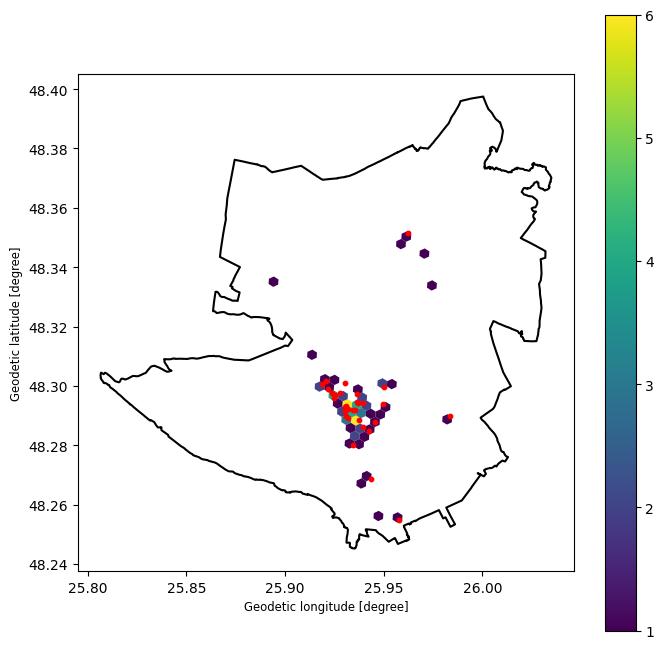

комірок з пам'ятками: 41, половина пам'яток у 10 з них


In [27]:
import h3
from shapely.geometry import Polygon

H3_RES = 9
print('середнє ребро комірки: %.0f м' % h3.average_hexagon_edge_length(H3_RES, unit='m'))

# ----- ВАШ КОД -----
cand['h3'] = [h3.latlng_to_cell(p.y, p.x, H3_RES) for p in cand.geometry.representative_point()]
dens = cand['h3'].value_counts()
hexes = gpd.GeoDataFrame(
    {'n': dens.values},
    geometry=[Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(c)]) for c in dens.index],
    crs='EPSG:4326')

ax = hexes.plot(column='n', legend=True, figsize=(8, 8))
boundary.boundary.plot(ax=ax, color='black')
pts30.plot(ax=ax, color='red', markersize=10)
plt.show()

half = int((dens.cumsum() < len(cand) / 2).sum()) + 1
print('комірок з пам\'ятками: %d, половина пам\'яток у %d з них' % (len(dens), half))

**Висновок до завдання 7.1:**

72 кандидати розкладено по 41 комірці H3 рівня 9 (ребро ~200 м), у найщільніших по 6 пам'яток. Половина пам'яток (36 з 72) зосереджена лише в 10 комірках, тобто майже на чверті зайнятих комірок - це історичний центр, решта точок поодинокі й розкидані по місту. 

Для маршруту це означає форму "щільне ядро + далекі виїзди": більшість точок обходяться короткими переходами в центрі, а основну довжину маршруту на 30 точках дають кілька віддалених об'єктів на півночі, півдні та сході міста. Саме для таких точок важливий порядок обходу, бо зайвий виїзд з центру коштує кілометри.

> **Пастка.** `h3.cell_to_boundary` повертає пари **(lat, lng)**, а
> `shapely.Polygon` чекає **(x, y)**, тобто (lng, lat). Переплутаєте — місто
> опиниться в Індійському океані. Це видно одразу, тому дивіться на карту.

### Питання до звіту

У скількох комірках зосереджено половину всіх пам'яток вашого міста?
Що це говорить про форму маршруту?

---
## 8. Просторове поєднання

### Завдання 8.1

Для кожної точки маршруту знайдіть найближчий заклад із шару `amenities`
(`sjoin_nearest`) і виведіть таблицю з відстанню в метрах.

Нагадування: `sjoin_nearest` рахує в одиницях CRS. У градусах результат буде
безглуздим — перепроєктуйте обидва шари в метричну систему.

In [28]:
# ----- ВАШ КОД -----
near = gpd.sjoin_nearest(pts10.to_crs(32635),
                         amenities.to_crs(32635)[['name', 'amenity', 'geometry']],
                         how='left', distance_col='відстань_м')
display(near[['name_left', 'name_right', 'amenity', 'відстань_м']].round(1))

,name_left,name_right,amenity,відстань_м
0,"СТАРТ: Залізничний вокзал ""Чернівці""",<NA>,toilets,33.2
1,Музей Володимира Івасюка,Гарячий Чебурек,restaurant,348.0
2,Костел Воздвиження Святого Христа,Гауптвахта,cafe,23.7
3,Музей Буковинської Діаспори,<NA>,toilets,146.5
4,Музей пожежно-рятувальної справи,Долина Плюс питна вода,drinking_water,56.8
5,Художній музей,Літературне кафе,cafe,10.1
6,Музей етнографії та стародавньої історії,<NA>,toilets,34.9
7,Турецька криниця,La Multi ani,restaurant,130.3
8,Чернівецький літературно-меморіальний музей Ол...,Гарячий Чебурек,restaurant,172.7
9,Музей Авіації та Космонавтики,Самоцвіти,cafe,128.7


**Висновок до завдання 8.1:**

Для кожної з 11 точок маршруту знайдено найближчий заклад; обидва шари переведено у метри. Медіана - 57 м, у 6 з 11 точок заклад ближче 100 м: біля більшості пам'яток кафе, ресторан чи туалет є в межах хвилини ходьби. Найдалі - музей Івасюка, 348 м до найближчого закладу. Серед найближчих - 4 ресторани, 3 кафе, 3 туалети і 1 точка питної води; туалети в OSM без назви, тому в таблиці в них порожнє ім'я. Відстань пряма, а не пішохідна, але для оцінки "що поруч" цього досить.

---
## 9. Маршрут на карті

Лінія маршруту — це **геометрія ребер графа**, а не відрізки між пам'ятками.

### Завдання 9.1

Побудуйте карту, на якій **обидві** лінії: справжній маршрут по ребрах і
прямі відрізки між точками. Різниця має бути видно оком.

In [29]:
node_xy = nodes.set_index('osmid')[['x', 'y']]

def route_coords(tour, ids):
    """Координати маршруту по ребрах графа у форматі (lat, lon) для folium."""
    coords = []
    for a, b in zip(tour[:-1], tour[1:]):
        try:
            path = nx.shortest_path(G, ids[a], ids[b], weight='length')
        except nx.NetworkXNoPath:
            path = [ids[a], ids[b]]
        for nd in path:
            coords.append((float(node_xy.loc[nd, 'y']), float(node_xy.loc[nd, 'x'])))
    return coords

# ----- ВАШ КОД: folium.Map(..., tiles=BASEMAP), дві PolyLine, маркери з номерами -----
road = route_coords(ex10, ids10)
straight = [(pts10.geometry.y.iloc[i], pts10.geometry.x.iloc[i]) for i in ex10]

fmap = folium.Map(location=straight[0], zoom_start=14, tiles=BASEMAP)
folium.PolyLine(road, color='blue', weight=4, tooltip='по ребрах графа').add_to(fmap)
folium.PolyLine(straight, color='red', weight=2, dash_array='6', tooltip='прямі відрізки').add_to(fmap)
for step, i in enumerate(ex10[:-1]):
    folium.Marker(straight[step], tooltip='%d. %s' % (step, pts10['name'].iloc[i]),
                  icon=folium.DivIcon(html='<b style="font-size:14px">%d</b>' % step)).add_to(fmap)
fmap.fit_bounds(road)
fmap.save('lr5_маршрут.html')
fmap

---
## 10. Результати для лабораторної роботи № 8

Збережіть файл, який ЛР8 прочитає і спробує побити.

In [30]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'місто': CITY,
    'мала_задача': {
        'точок': len(ids10),
        'оптимум_м': round(L_opt, 1),
        'оптимальний_порядок': [str(pts10['name'].iloc[i]) for i in ex10],
        'найближчий_сусід_м': round(tour_length(D10, nn10), 1),
        'двоопт_м': round(tour_length(D10, op10), 1),
    },
    'велика_задача': {
        'точок': len(ids30),
        'найближчий_сусід_м': round(L_nn30, 1),
        'двоопт_м': round(L_op30, 1),
        'двоопт_с': round(t_op30, 4),
        'точки': [{'name': str(pts30['name'].iloc[i]),
                   'lat': float(pts30.geometry.y.iloc[i]),
                   'lon': float(pts30.geometry.x.iloc[i])} for i in range(len(pts30))],
        'матриця_віддалей_м': [[None if not np.isfinite(v) else round(float(v), 1)
                                for v in row] for row in D30],
    },
}
with open('lr5_результати.json', 'w', encoding='utf-8') as f:
    json.dump(result, f, ensure_ascii=False, indent=1)
print('збережено lr5_результати.json (%.1f КБ)' % (os.path.getsize('lr5_результати.json') / 1024))

збережено lr5_результати.json (16.2 КБ)


---
## 11. Звіт

Відповіді пишіть просто в наступній комірці, числами зі своїх обчислень.

1. **Скільки об'єктів ви відкинули** на кроці 2 і за яким правилом? Чи погодились
   би ви віддати цей фільтр замовнику без пояснень?
2. **Які сигнали ввійшли у ваш рейтинг і з якими вагами?** Чому саме так?
3. **Скільки об'єктів збіглося** у ваших двох рейтингах із десяти? Що це
   означає для слова «найкращі»?
4. **Який у вас коефіцієнт обходу** і чи типовий він? Якщо ні — що в місті
   його пояснює?
5. **На скільки відсотків** найближчий сусід гірший за точний розв'язок?
   Чи здивувало вас це число?
6. **Чому точний розв'язок на 30 точках недоступний?** Назвіть конкретну
   величину, яка цьому заважає.
7. **Що у ваших даних виявилось неправильним** — дублікати, пропущені назви,
   об'єкти не на місці? Як ви з цим вчинили?

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-помічником, у яких саме місцях і як перевіряли
отриманий код. Використання дозволене; **неперевірене** використання — ні.

In [31]:
REPORT = '''
1. Відкинуто 21 об'єкт з 93. Маска нічого не відсіяла, бо запит до Overpass уже був зроблений з цими тегами;
правило "має name" прибрало 21 безіменний об'єкт, тому лишилось 72 кандидати. 
Замовнику без пояснень такий фільтр не віддав би: він пропускає 32 меморіали, серед них меморіальні дошки, але серед кандидатів немає головних пам'яток міста, бо в OSM вони позначені іншими тегами.

2. score = 0.4 wiki + 0.3 n_lang + 0.2 visit + 0.1 area, кожен сигнал зведено до шкали 0-1 через rank(pct=True). 
Ваги від найсильнішого сигналу до найслабшого: 
- стаття у Вікіпедії чи Вікіданих - незалежне визнання, але рідкісне (7 з 72); 
- кількість мов назви - інтерес іноземців, має кілька рівнів (1-6 мов); 
- музей чи галерея - призначені для відвідування, але їх 13; 
- площа - найслабший сигнал, вона є лише у 4 об'єктів. 
- historic не взято: його мають 41 з 72 кандидатів і жоден музей, тобто тут він означав би "не музей".

3. Збіглося 4 з 10: площа більша за нуль лише у 4 об'єктів, решта топу "за площею" - нулі в порядку таблиці. 
Тобто "найкращі" визначає обраний критерій, а не дані: з тих самих даних тим самим кодом виходять різні списки.

4. Коефіцієнт обходу 1.20 для 10 точок і 1.21 для 30 - нижня межа типового діапазону 1.2-1.6. 
Пішохідна мережа в центрі густа, а між точками маршруту немає перешкод, які довелося б обходити. 
Недосяжних пар немає, асиметрія 0 м, бо пішки кожною вулицею можна йти в обидва боки.

5. Найближчий сусід гірший за точний розв'язок на 11.88 % (16.9 км проти 15.1 км). 
Саме число не здивувало: жадібний метод під кінець змушений повертатись до пропущених далеких точок. 
Здивувало інше - 2-opt зменшує похибку до 0.73 %, тобто майже до оптимуму.

6. Заважає пам'ять: таблиця Held-Karp для n = 31 має 2^30 x 30 ≈ 32 млрд клітин, це ~258 ГБ при 8 байтах на клітину, 
а в комп'ютері ~16 ГБ оперативної пам'яті - у 16 разів менше. Час теж зростає як 2^(n-1) x (n-1)^2 (~10^12 операцій), але першою закінчується пам'ять.

7. "Німецький будинок" внесений в OSM двічі (точки за 4.9 м) - один прибрано через drop_duplicates('name'), 
інакше дві точки дали б майже нульову віддаль. 21 об'єкт без назви відкинуто. 
Дві пари ближче 60 м (Вуличне мистецтво - Steinbarg, Костел Воздвиження - "600 років моєму рідному місту") - різні сусідні об'єкти, їх лишено. 
Площа є лише у 4 з 72 кандидатів, тому критерій площі майже не працює. 
Головне: серед кандидатів немає найвідоміших пам'яток Чернівців (Резиденція митрополитів - об'єкт ЮНЕСКО, Ратуша, театр), тож рейтинг "найкращих" обмежений не формулою, а тим, як люди розмітили OSM. 
У межах завдання це не виправлялось, але зафіксовано як обмеження даних.

Декларація про використання ШІ:
Користувався Claude Opus 5.5 як помічником: пояснення завдань, код для fetch, чернетки висновків, розбирав кожну функцію перед запуском.
'''
print(REPORT)


1. Відкинуто 21 об'єкт з 93. Маска нічого не відсіяла, бо запит до Overpass уже був зроблений з цими тегами;
правило "має name" прибрало 21 безіменний об'єкт, тому лишилось 72 кандидати. 
Замовнику без пояснень такий фільтр не віддав би: він пропускає 32 меморіали, серед них меморіальні дошки, але серед кандидатів немає головних пам'яток міста, бо в OSM вони позначені іншими тегами.

2. score = 0.4 wiki + 0.3 n_lang + 0.2 visit + 0.1 area, кожен сигнал зведено до шкали 0-1 через rank(pct=True). 
Ваги від найсильнішого сигналу до найслабшого: 
- стаття у Вікіпедії чи Вікіданих - незалежне визнання, але рідкісне (7 з 72); 
- кількість мов назви - інтерес іноземців, має кілька рівнів (1-6 мов); 
- музей чи галерея - призначені для відвідування, але їх 13; 
- площа - найслабший сигнал, вона є лише у 4 об'єктів. 
- historic не взято: його мають 41 з 72 кандидатів і жоден музей, тобто тут він означав би "не музей".

3. Збіглося 4 з 10: площа більша за нуль лише у 4 об'єктів, решта топу "за 